# Phase 1: Exploratory data analysis (FD001)

**Goal:** understand how the engines wear out and which sensors show it, before any modeling.

FD001 is the simplest C-MAPSS subset: one operating condition and one failure mode (high-pressure compressor degradation). Each row is one engine at one cycle (one flight).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from pipeline.check_raw_data import COLS, load  # same loader the pipeline uses

FIG = ROOT / "docs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

train = load(ROOT / "data/raw/train_FD001.txt")
test = load(ROOT / "data/raw/test_FD001.txt")
true_rul = pd.read_csv(ROOT / "data/raw/RUL_FD001.txt", header=None, names=["RUL"])
print("train:", train.shape, "| test:", test.shape, "| engines:", train.unit.nunique(), "/", test.unit.nunique())
train.head()

train: (20631, 26) | test: (13096, 26) | engines: 100 / 100


,unit,cycle,setting1,setting2,setting3,s1,s2,s3,s4,s5,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 1. How long do engines last?

**Concept:** every training engine runs until it fails, so its last cycle is its lifetime.
**Why:** the spread of lifetimes tells us how hard prediction is. If all engines failed at the same cycle, a simple average would be enough.

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


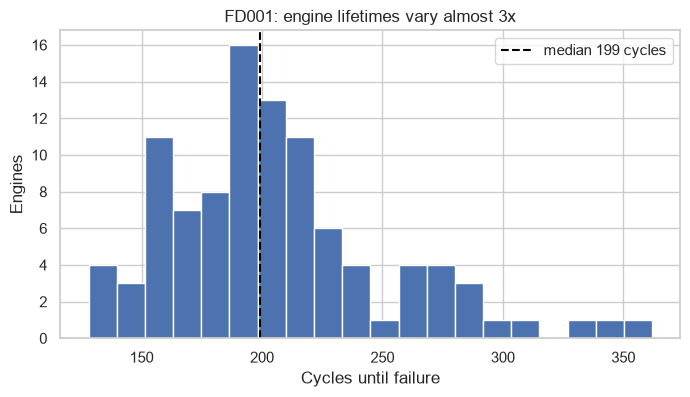

In [2]:
life = train.groupby("unit")["cycle"].max()
print(life.describe().round(1))

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(life, bins=20, color="#4C72B0", edgecolor="white")
ax.axvline(life.median(), color="black", linestyle="--", label=f"median {life.median():.0f} cycles")
ax.set(title="FD001: engine lifetimes vary almost 3x", xlabel="Cycles until failure", ylabel="Engines")
ax.legend()
fig.savefig(FIG / "fd001_lifetimes.png", dpi=150, bbox_inches="tight")

## 2. Which sensors never change?

**Concept:** a sensor with zero (or near-zero) spread carries no information about wear.
**Why:** dropping useless inputs makes models faster and less noisy, and each drop needs a reason we can state.

In [3]:
cols = [c for c in COLS if c not in ("unit", "cycle")]
spread = pd.DataFrame({
    "std": train[cols].std(),
    "distinct_values": train[cols].nunique(),
}).sort_values("std")
spread.round(5)

,std,distinct_values
s1,0.00000,1
setting3,0.00000,1
s10,0.00000,1
s19,0.00000,1
s18,0.00000,1
s16,0.00000,1
s5,0.00000,1
setting2,0.00029,13
s6,0.00139,2
setting1,0.00219,158


In [4]:
constant = spread.index[spread.distinct_values <= 2].tolist()
settings = ["setting1", "setting2", "setting3"]
sensors = [c for c in cols if c.startswith("s") and c not in settings and c not in constant]
print("Drop (constant or two-valued):", constant)
print("Operating settings (one condition in FD001, used only for checks):", settings)
print(f"Keep {len(sensors)} sensors:", sensors)

Drop (constant or two-valued): ['s1', 'setting3', 's10', 's19', 's18', 's16', 's5', 's6']
Operating settings (one condition in FD001, used only for checks): ['setting1', 'setting2', 'setting3']
Keep 14 sensors: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']


## 3. How do the useful sensors change as engines age?

**Concept:** plotting each sensor against *cycles before failure* lines every engine up at its failure point, so the wear trend becomes visible.
**Why:** sensors that drift steadily toward failure carry the signal the model will learn from.

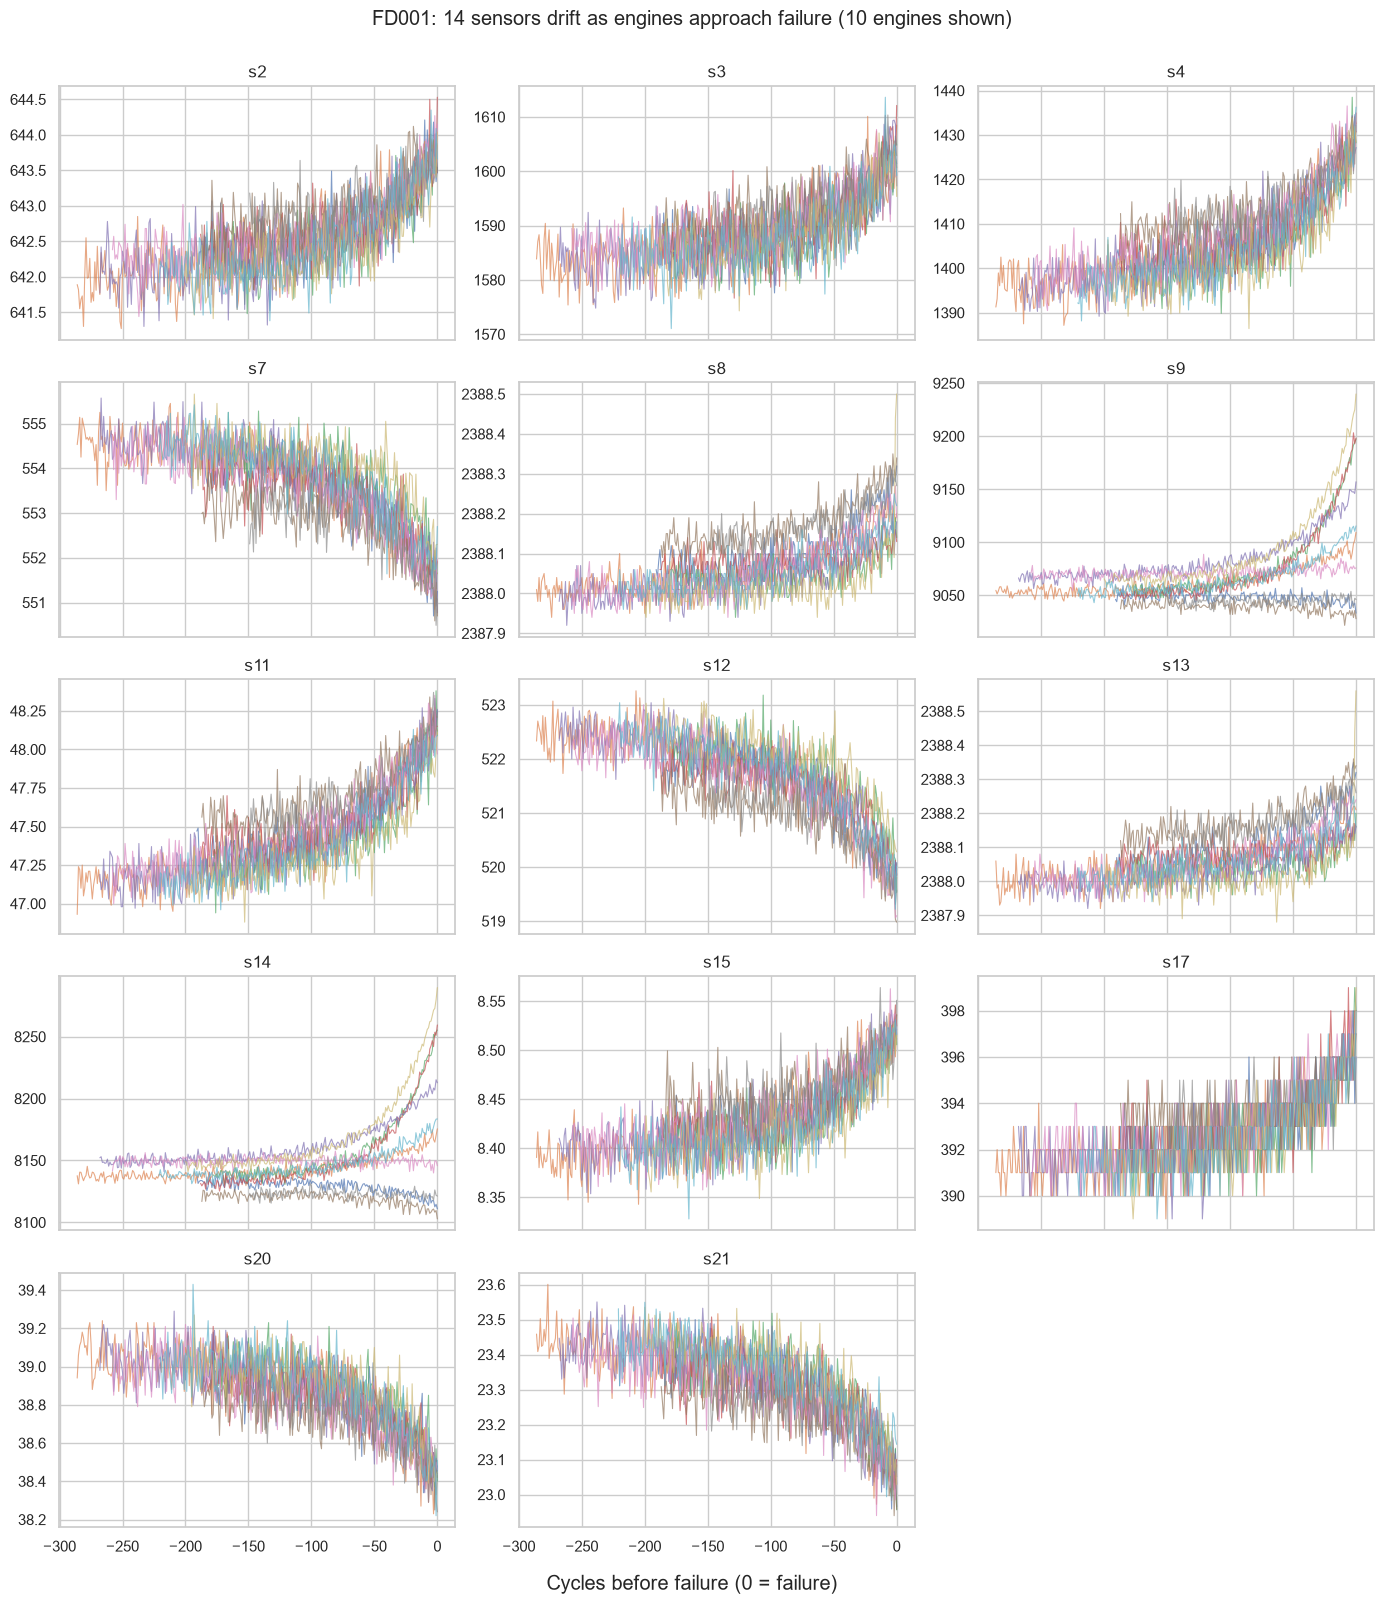

In [5]:
train["RUL"] = train.groupby("unit")["cycle"].transform("max") - train["cycle"]
sample = train[train.unit.isin(range(1, 11))]

fig, axes = plt.subplots(5, 3, figsize=(14, 16), sharex=True)
for ax, s in zip(axes.flat, sensors):
    for _, g in sample.groupby("unit"):
        ax.plot(-g.RUL, g[s], linewidth=0.8, alpha=0.7)
    ax.set_title(s)
for ax in axes.flat[len(sensors):]:
    ax.remove()
fig.supxlabel("Cycles before failure (0 = failure)")
fig.suptitle("FD001: 14 sensors drift as engines approach failure (10 engines shown)", y=1.0)
fig.tight_layout()
fig.savefig(FIG / "fd001_sensor_trends.png", dpi=150, bbox_inches="tight")

## 4. Which sensors are most linked to remaining life?

**Concept:** correlation runs from -1 to +1. A strong negative value means the sensor rises as remaining life falls.
**Why:** it ranks the sensors and exposes near-duplicates (pairs that carry the same information).

s11   -0.696
s4    -0.679
s12    0.672
s7     0.657
s15   -0.643
s21    0.636
s20    0.629
s2    -0.606
s17   -0.606
s3    -0.585
s8    -0.564
s13   -0.563
s9    -0.390
s14   -0.307


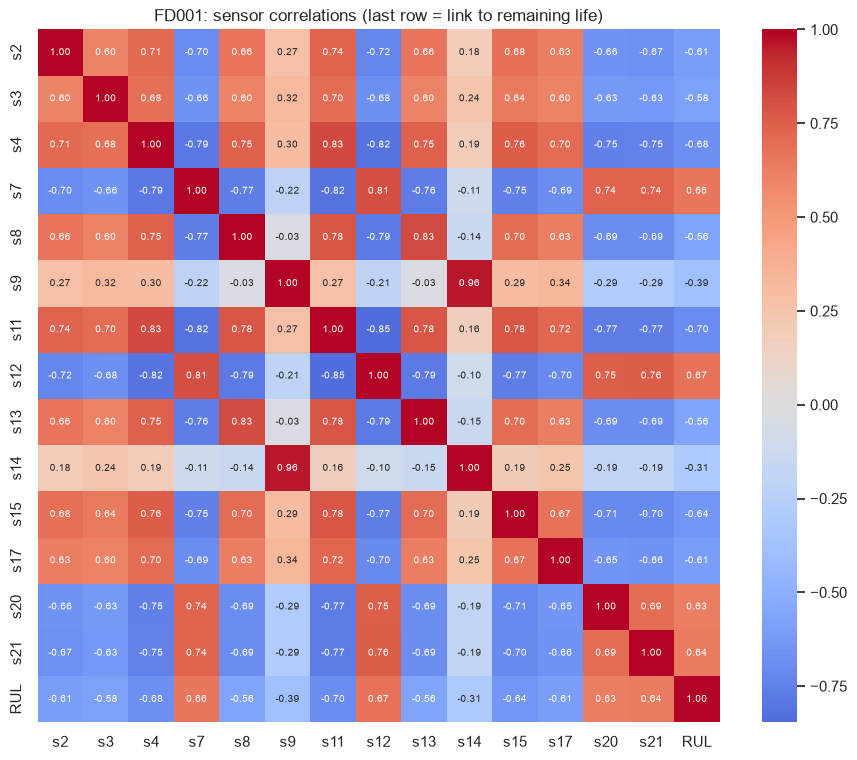

In [6]:
corr_rul = train[sensors + ["RUL"]].corr()["RUL"].drop("RUL").sort_values(key=abs, ascending=False)
print(corr_rul.round(3).to_string())

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(train[sensors + ["RUL"]].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f",
            annot_kws={"size": 7}, ax=ax)
ax.set_title("FD001: sensor correlations (last row = link to remaining life)")
fig.savefig(FIG / "fd001_correlations.png", dpi=150, bbox_inches="tight")

In [7]:
pairs = train[sensors].corr().abs()
dupes = [(a, b, round(pairs.loc[a, b], 3)) for i, a in enumerate(sensors) for b in sensors[i + 1:] if pairs.loc[a, b] > 0.9]
print("Sensor pairs with |correlation| > 0.9:", dupes)

Sensor pairs with |correlation| > 0.9: [('s9', 's14', np.float64(0.963))]


## 5. What does the test set look like?

**Concept:** test engines stop before failure. We predict remaining life at each engine's last observed cycle and score against `RUL_FD001.txt`.
**Why:** this decides the RUL cap (Phase 3) and tells us how much history the models will see for each engine.

In [8]:
observed = test.groupby("unit")["cycle"].max()
print("Cycles observed per test engine:", observed.describe().round(1).to_dict())
print("True remaining life:", true_rul.RUL.describe().round(1).to_dict())
print(f"Test engines with true RUL above 125: {(true_rul.RUL > 125).mean():.0%}")

Cycles observed per test engine: {'count': 100.0, 'mean': 131.0, 'std': 53.6, 'min': 31.0, '25%': 88.8, '50%': 133.5, '75%': 164.2, 'max': 303.0}
True remaining life: {'count': 100.0, 'mean': 75.5, 'std': 41.8, 'min': 7.0, '25%': 32.8, '50%': 86.0, '75%': 112.2, 'max': 145.0}
Test engines with true RUL above 125: 11%


## Findings

See `docs/EDA_FINDINGS.md` for the written summary and the decisions they lead to.